# Lab 2 - Task 1 — CNN trained from scratch on mel-spectrograms
**Machine Learning for Sound and Music**

This notebook trains and optimises a small convolutional neural network on the GTZAN mel-spectrogram images and evaluates it, once, on a held-out 20 % test set. First a setup is done, then splitting and preprocessing the images, then a few versions of the CNN are trained and compared on the validation split, and finally the final model is retrained on the full 80% and evaluated on the 20%

**Protocol.** Every hyperparameter is chosen with the validation split carved out of the *training* songs only. The test set is never used for selection; it is evaluated once, with the selected configuration.

**Outputs** (all written to `results_task1/`, the file names are read by the later notebooks):

| File | Content |
|---|---|
| `split_ids.json` | Train / test song identifiers (shared by all models) |
| `task1_experiments.csv` | Validation results of the 16 configurations |
| `task1_final.csv` | Test accuracy, parameters, training and inference time of the final CNN |
| `task1_test_predictions.csv`, `task1_test_probs.npy` | Test predictions and class probabilities (same song order) |
| `task1_best_cnn.keras` | Final trained model |
| `task1_fig_*.png` | Figures used in the report |

## Setup

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import shutil
from pathlib import Path

PROJECT      = Path("/content/drive/MyDrive/MSC/music-genre-classification-2")
SRC_IMAGES   = PROJECT / "data" / "images_original"      # spectrograms on Drive
LOCAL_IMAGES = Path("/content/data/images_original")     # local copy (faster I/O)
RESULTS_DIR  = PROJECT / "results_task1"
RESULTS_DIR.mkdir(exist_ok=True)
SEED           = 42      # main partition

"""GPU kernels are not fully deterministic, so retraining the final model gives slightly different
test accuracies from run to run (see the report, Section 2.3).
With `RETRAIN_FINAL = False` the notebook reloads the saved final model and predictions if they exist,
so the numbers in the report are reproduced exactly. Set it to `True` to retrain and overwrite them."""

RETRAIN_FINAL  = False   # False: reload the saved final model/predictions if available

assert SRC_IMAGES.exists(), f"Spectrogram folder not found: {SRC_IMAGES}"

n_local = len(list(LOCAL_IMAGES.glob("*/*.png"))) if LOCAL_IMAGES.exists() else 0
if n_local < 900:
    print("Copying spectrograms to local disk ...")
    shutil.copytree(SRC_IMAGES, LOCAL_IMAGES, dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns(".DS_Store", "._*"))
print("Local PNG files:", len(list(LOCAL_IMAGES.glob("*/*.png"))))

Mounted at /content/drive
Copying spectrograms to local disk ...
Local PNG files: 999


In [ ]:
import re, json, time, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, f1_score)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMG_DIR = LOCAL_IMAGES
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "axes.spines.top": False,
                     "axes.spines.right": False})

def set_seed(s):
    random.seed(s); np.random.seed(s); keras.utils.set_random_seed(s)
set_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow", tf.__version__, "| GPUs:", gpus)
if not gpus:
    print("WARNING: no GPU available - training will be very slow.")

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Data

One row per spectrogram. Songs are identified as `genre.NNNNN` (e.g. `blues.00000`), the same format used by the Lab 1 preprocessing pipeline. Labels are encoded alphabetically, exactly as the `LabelEncoder` of Lab 1.

In [ ]:
pat  = re.compile(r'^([a-z]+)(\d{5})\.png$')          # e.g. blues00000.png
rows = []
for gdir in sorted(p for p in IMG_DIR.iterdir() if p.is_dir()):
    for f in sorted(gdir.glob('*.png')):
        m = pat.match(f.name)
        if m:
            rows.append(dict(song=f'{m.group(1)}.{m.group(2)}', genre=m.group(1), path=str(f)))

songs = pd.DataFrame(rows)
GENRES = sorted(songs.genre.unique())
songs['label'] = songs.genre.map({g: i for i, g in enumerate(GENRES)})
print(len(songs), 'songs'); print(songs.genre.value_counts().to_string())

999 songs
genre
blues        100
classical    100
country      100
disco        100
hiphop       100
metal        100
reggae       100
pop          100
rock         100
jazz          99


#### Train / validation / test partition

Stratified 80/20 split by genre (799 training and 200 test songs). To keep every model comparable song by song, the test songs must be exactly those used in Task 2 (split_seed42.json). If that file exists it takes precedence. A second, inner split (80/20 of the training songs only, 639 / 160) is used to choose the configuration.



In [ ]:
tr, te = train_test_split(songs.song, test_size=0.2, stratify=songs.genre, random_state=SEED)
split = dict(train=sorted(tr), test=sorted(te))

# Align with Task 2: if its split exists, the test songs must be exactly the same
TASK2_SPLIT = PROJECT / "split_seed42.json"
if TASK2_SPLIT.exists():
    s2 = json.load(open(TASK2_SPLIT))

    def to_id(p):                                          # '.../blues/blues00000.png' -> 'blues.00000'
        p = Path(p); g = p.parent.name
        return f"{g}.{p.stem[len(g):]}"

    te2 = sorted(to_id(p) for p in s2["test"])
    assert set(te2) <= set(songs.song), "The Task 2 split contains songs that are not in images_original"
    same = te2 == split["test"]
    print("Test set identical to Task 2:", same)
    if not same:
        print("-> using the Task 2 test set so that all models are evaluated on the same songs")
        te_set = set(te2)
        split = dict(train=sorted(s for s in songs.song if s not in te_set), test=te2)
else:
    print("No Task 2 split found on Drive; using train_test_split (seed 42).")

# Inner validation split, drawn ONLY from the training songs (used to choose the configuration)
tr_songs = songs[songs.song.isin(split["train"])]
sub_tr, sub_va = train_test_split(tr_songs.song, test_size=0.2, stratify=tr_songs.genre, random_state=SEED)

idx_of = lambda names: songs.index[songs.song.isin(set(names))].to_numpy()
IDX_TRAIN, IDX_TEST = idx_of(split["train"]), idx_of(split["test"])
IDX_SUB_TR, IDX_VAL = idx_of(sub_tr), idx_of(sub_va)

print(f"train {len(IDX_TRAIN)} | test {len(IDX_TEST)} | inner split: train {len(IDX_SUB_TR)}, validation {len(IDX_VAL)}")
assert not set(IDX_TRAIN) & set(IDX_TEST)
assert not set(IDX_SUB_TR) & set(IDX_VAL) and set(IDX_SUB_TR) | set(IDX_VAL) == set(IDX_TRAIN)

# Song identifiers, same format as the Lab 1 pipeline (test_groups=split["test"])
json.dump(split, open(RESULTS_DIR / "split_ids.json", "w"), indent=1)

Test set identical to Task 2: True
train 799 | test 200 | inner split: train 639, validation 160


#### Spectrogram preprocessing
The provided images are 432 × 288 RGBA renderings of a colour-mapped mel-spectrogram drawn inside a white matplotlib figure frame (axes, margins). The frame is identical for every song and carries no information, so each image is:

1. **Cropped** to the rectangle with corners (55, 37) and (387, 250) pixels, which keeps only the spectrogram (332 × 213 px)
2. **Converted** from RGBA to RGB
3. **Resized** (bilinear) to 128 × 192 pixels (frequency × time); the horizontal axis is time (30 s) and the vertical axis is mel frequency (low frequencies at the bottom)
4. **Standardised** per colour channel with the mean and standard deviation of the *training* songs only

The three colour channels are kept so that the same data can feed the pretrained networks of Task 2.

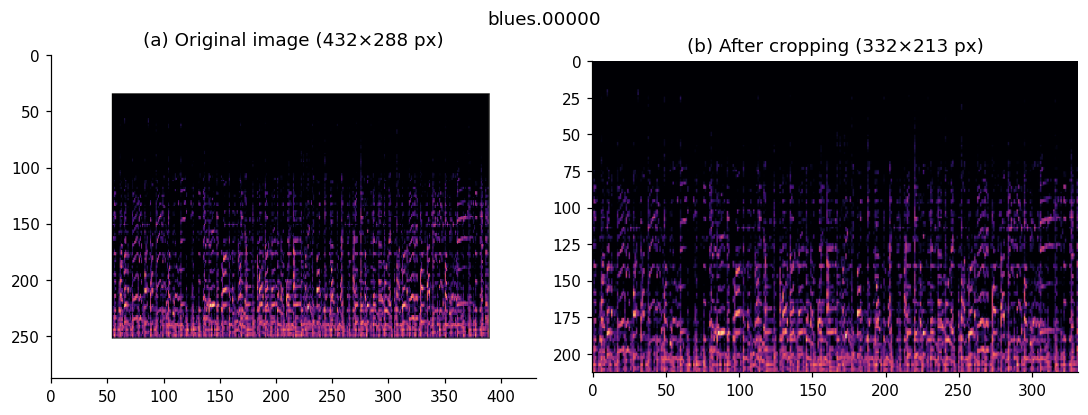

Original image: (432, 288) RGBA
(999, 128, 192, 3) 74 MB
channel mean: [0.147 0.051 0.172] | std: [0.21  0.078 0.173]


In [ ]:
IMG_H, IMG_W = 128, 192        # height (frequency) x width (time)
CROP = (55, 37, 387, 250)      # (left, top, right, bottom) in pixels of the original image

def load_img(p):
    im = Image.open(p).convert("RGB").crop(CROP)                       # RGBA -> RGB, remove the frame
    return np.asarray(im.resize((IMG_W, IMG_H), Image.BILINEAR))       # H x W x 3, uint8

# Visual check: before / after cropping (nothing white and no axes should remain)
im0 = Image.open(songs.path[0])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].imshow(im0);                                  ax[0].set_title(f"(a) Original image ({im0.size[0]}×{im0.size[1]} px)")
ax[1].imshow(im0.convert("RGB").crop(CROP));        ax[1].set_title("(b) After cropping (332×213 px)")
fig.suptitle(songs.song[0]); fig.tight_layout()
fig.savefig(RESULTS_DIR / "task1_fig_crop.png", dpi=200, bbox_inches="tight"); plt.show()
print("Original image:", im0.size, im0.mode)

# Load all spectrograms in memory
X_all = np.stack([load_img(p) for p in songs.path])                    # N x H x W x 3, uint8
y_all = songs.label.to_numpy()
print(X_all.shape, f"{X_all.nbytes / 1e6:.0f} MB")

# Normalisation statistics from the training songs only
_tr  = X_all[IDX_TRAIN].astype("float32") / 255.
MEAN = _tr.mean((0, 1, 2)); STD = _tr.std((0, 1, 2)); del _tr
print("channel mean:", MEAN.round(3), "| std:", STD.round(3))

Training images are augmented on the fly: one random band of up to 16 consecutive frequency rows and one of up to 24 consecutive time columns (12.5 % of each axis) are set to the mean value (zero after standardisation). The positions change for every song and every epoch. Validation and test images are never augmented.

In [ ]:
def spec_mask(x, y, fmask=16, tmask=24):
    # One frequency band and one time band, set to 0 (= the mean after standardisation)
    f = tf.random.uniform([], 0, fmask + 1, tf.int32); f0 = tf.random.uniform([], 0, IMG_H - f + 1, tf.int32)
    t = tf.random.uniform([], 0, tmask + 1, tf.int32); t0 = tf.random.uniform([], 0, IMG_W - t + 1, tf.int32)
    rows, cols = tf.range(IMG_H), tf.range(IMG_W)
    row_m = (rows >= f0) & (rows < f0 + f)                  # frequency band
    col_m = (cols >= t0) & (cols < t0 + t)                  # time band
    mask  = row_m[:, None] | col_m[None, :]                 # H x W
    return tf.where(mask[:, :, None], 0.0, x), y

def make_ds(idx, augment=False, bs=32, shuffle=False):
    x  = (X_all[idx].astype("float32") / 255. - MEAN) / STD
    ds = tf.data.Dataset.from_tensor_slices((x, y_all[idx]))
    if shuffle: ds = ds.shuffle(len(idx), seed=SEED)
    if augment: ds = ds.map(spec_mask, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(bs).prefetch(tf.data.AUTOTUNE)

# Changing the input size reloads the images at the new size and recomputes MEAN/STD (train songs only)
SIZE_CACHE = {(IMG_H, IMG_W): (X_all, MEAN, STD)}

def set_input_size(h, w):
    global X_all, MEAN, STD, IMG_H, IMG_W
    if (h, w) not in SIZE_CACHE:
        X = np.stack([np.asarray(Image.open(p).convert("RGB").crop(CROP).resize((w, h), Image.BILINEAR))
                      for p in songs.path])
        t = X[IDX_TRAIN].astype("float32") / 255.
        SIZE_CACHE[(h, w)] = (X, t.mean((0, 1, 2)), t.std((0, 1, 2)))
    X_all, MEAN, STD = SIZE_CACHE[(h, w)]
    IMG_H, IMG_W = h, w

## Models and Training

We have a class to configurate different CNNs. A stack of identical blocks — **3 × 3 convolution (same padding) → batch normalisation → ReLU → 2 × 2 max-pooling** — followed by global average pooling, dropout and a dense layer with 10 logits. Global average pooling keeps the parameter count small (no large dense layer on a flattened map) and makes the classifier independent of the input size.

In [ ]:
def SimpleCNN(filters=(16, 32, 64), kernel=(3, 3), dropout=0.3, n_classes=10, input_shape=None):
    # filters: one entry per conv block | kernel: (height = frequency, width = time)
    input_shape = input_shape or (IMG_H, IMG_W, 3)
    inp = keras.Input(shape=input_shape)
    x = inp
    for f in filters:
        x = layers.Conv2D(f, kernel, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    return keras.Model(inp, layers.Dense(n_classes)(x))     # logits

# Trainable parameters only (BatchNorm moving statistics are not counted)
n_params = lambda m: int(sum(np.prod(tuple(w.shape)) for w in m.trainable_weights))

For training we use AdamW (weight decay 1e-4) with a cosine learning-rate schedule over `epochs`, batch size 32 and cross-entropy on the logits. When a validation set is given, early stopping on validation accuracy (patience 10, best weights restored) is used. `stop_epochs` stops training before the end of the schedule *without changing it*; it is used to retrain the final model with the same dynamics as in the search.

In [ ]:
def predict_logits(model, idx, bs=128):
    return model.predict(make_ds(idx, bs=bs), verbose=0)

def predict(model, idx, bs=128):
    return predict_logits(model, idx, bs).argmax(1)

def train_model(model, tr_idx, va_idx=None, epochs=40, lr=1e-3, wd=1e-4, bs=32,
                augment=True, patience=10, seed=SEED, verbose=0, stop_epochs=None):
    # `epochs` fixes the length of the cosine schedule; `stop_epochs` (optional) stops earlier
    # without changing the schedule.
    set_seed(seed)
    steps = int(np.ceil(len(tr_idx) / bs)) * epochs
    model.compile(
        optimizer=keras.optimizers.AdamW(
            learning_rate=keras.optimizers.schedules.CosineDecay(lr, steps), weight_decay=wd),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"])
    cbs = []
    if va_idx is not None:
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                                 patience=patience, restore_best_weights=True))
    n_ep = stop_epochs or epochs
    t0 = time.time()
    h = model.fit(make_ds(tr_idx, augment, bs, shuffle=True),
                  validation_data=make_ds(va_idx) if va_idx is not None else None,
                  epochs=n_ep, callbacks=cbs, verbose=verbose,
                  shuffle=False)                              # the dataset is already shuffled in make_ds
    hist = pd.DataFrame(h.history); hist.insert(0, "epoch", range(1, len(hist) + 1))
    if va_idx is not None:
        best_val, best_epoch = float(hist.val_accuracy.max()), int(hist.val_accuracy.idxmax()) + 1
    else:
        best_val, best_epoch = None, n_ep
    return dict(model=model, history=hist, best_val=best_val, best_epoch=best_epoch,
                train_time=time.time() - t0, params=n_params(model))

## Configuration Search

The search runs in two stages on the inner split (639 training / 160 validation songs). Every result is appended to `task1_experiments.csv` as soon as it finishes, and finished configurations are skipped, so the search can be resumed after a disconnection.

1. **Stage 1 — depth and filters** (6 networks), with the remaining choices fixed: dropout 0.3, augmentation on, learning rate 1e-3, 3 × 3 kernels, 128 × 192 input.
2. **Stage 2 — one factor at a time** (10 networks) starting from the best stage-1 network: dropout, augmentation, learning rate, kernel shape and input size.

With 160 validation songs, one song is worth 0.6 pp and the standard error of an accuracy near 0.75 is about 3.4 pp, so differences of one or two points are within the noise.

In [ ]:
RESULTS_CSV = RESULTS_DIR / "task1_experiments.csv"

BASE0 = dict(filters=(32, 64, 128), kernel=(3, 3), dropout=0.3, augment=True, lr=1e-3, size=(128, 192))

DEPTH_EXPERIMENTS = {                                        # stage 1
    "2conv_16-32":             dict(filters=(16, 32)),
    "3conv_16-32-64":          dict(filters=(16, 32, 64)),
    "3conv_32-64-128":         dict(filters=(32, 64, 128)),
    "4conv_16-32-64-128":      dict(filters=(16, 32, 64, 128)),
    "4conv_32-64-128-256":     dict(filters=(32, 64, 128, 256)),
    "5conv_32-64-128-256-256": dict(filters=(32, 64, 128, 256, 256)),
}
FACTOR_EXPERIMENTS = {                                       # stage 2
    "dropout_0.0":     dict(dropout=0.0),
    "dropout_0.5":     dict(dropout=0.5),
    "no_augment":      dict(augment=False),
    "lr_3e-4":         dict(lr=3e-4),
    "lr_3e-3":         dict(lr=3e-3),
    "kernel_5x5":      dict(kernel=(5, 5)),
    "kernel_7x3_freq": dict(kernel=(7, 3)),                  # tall in frequency
    "kernel_3x7_time": dict(kernel=(3, 7)),                  # wide in time
    "size_64x96":      dict(size=(64, 96)),
    "size_192x288":    dict(size=(192, 288)),                # slowest: run last
}

def fmt(cfg):
    return dict(filters="-".join(map(str, cfg["filters"])), kernel="x".join(map(str, cfg["kernel"])),
                dropout=cfg["dropout"], augment=cfg["augment"], lr=cfg["lr"],
                img_h=cfg["size"][0], img_w=cfg["size"][1])

def run_experiments(exps, base, group):
    done = set(pd.read_csv(RESULTS_CSV).name) if RESULTS_CSV.exists() else set()    # resume if interrupted
    for name, over in exps.items():
        if name in done:
            print("skip (already done):", name); continue
        cfg = {**base, **over}
        print("=====", name, fmt(cfg))
        set_input_size(*cfg["size"])
        keras.backend.clear_session()
        out = train_model(SimpleCNN(filters=cfg["filters"], kernel=cfg["kernel"], dropout=cfg["dropout"]),
                          IDX_SUB_TR, IDX_VAL, lr=cfg["lr"], augment=cfg["augment"])
        row = dict(name=name, group=group, **fmt(cfg), depth=len(cfg["filters"]), params=out["params"],
                   best_val_acc=out["best_val"], best_epoch=out["best_epoch"], train_time_s=out["train_time"])
        pd.DataFrame([row]).to_csv(RESULTS_CSV, mode="a", header=not RESULTS_CSV.exists(), index=False)   # save immediately
        print({k: row[k] for k in ("best_val_acc", "best_epoch", "params", "train_time_s")})
    set_input_size(*BASE0["size"])

In [ ]:
# FIRST STAGE

run_experiments(DEPTH_EXPERIMENTS, BASE0, "depth")

depth_df = (pd.read_csv(RESULTS_CSV).query("group == 'depth'")
            .sort_values("best_val_acc", ascending=False, kind="stable"))
display(depth_df[["name", "params", "best_val_acc", "best_epoch", "train_time_s"]]
        .round({"best_val_acc": 3, "train_time_s": 1}).reset_index(drop=True))

skip (already done): 2conv_16-32
skip (already done): 3conv_16-32-64
skip (already done): 3conv_32-64-128
skip (already done): 4conv_16-32-64-128
skip (already done): 4conv_32-64-128-256
skip (already done): 5conv_32-64-128-256-256


,name,params,best_val_acc,best_epoch,train_time_s
0,4conv_32-64-128-256,391946,0.762,40,57.0
1,4conv_16-32-64-128,99210,0.744,40,38.4
2,3conv_32-64-128,94986,0.688,37,55.1
3,3conv_16-32-64,24458,0.594,38,39.1
4,5conv_32-64-128-256-256,982538,0.587,19,48.0
5,2conv_16-32,5514,0.463,24,37.4


In [ ]:
# SECOND STAGE

BASE = {**BASE0, "filters": tuple(map(int, depth_df.iloc[0].filters.split("-")))}
print("Base configuration for stage 2:", BASE)
run_experiments(FACTOR_EXPERIMENTS, BASE, "factor")

Base configuration for stage 2: {'filters': (32, 64, 128, 256), 'kernel': (3, 3), 'dropout': 0.3, 'augment': True, 'lr': 0.001, 'size': (128, 192)}
skip (already done): dropout_0.0
skip (already done): dropout_0.5
skip (already done): no_augment
skip (already done): lr_3e-4
skip (already done): lr_3e-3
skip (already done): kernel_5x5
skip (already done): kernel_7x3_freq
skip (already done): kernel_3x7_time
skip (already done): size_64x96
skip (already done): size_192x288


Results of the search

In [ ]:
res_df = (pd.read_csv(RESULTS_CSV)
          .sort_values("best_val_acc", ascending=False, kind="stable").reset_index(drop=True))
res_df["selected"] = res_df.index == 0

n_val = len(IDX_VAL)
print(f"{len(res_df)} configurations | 1 validation song = {100 / n_val:.2f} pp | "
      f"standard error of an accuracy of 0.75 = {100 * np.sqrt(.75 * .25 / n_val):.1f} pp\n")
display(res_df[["name", "group", "filters", "kernel", "dropout", "augment", "lr", "img_h", "img_w",
                "params", "best_val_acc", "best_epoch", "train_time_s", "selected"]]
        .round({"best_val_acc": 3, "train_time_s": 1}))

16 configurations | 1 validation song = 0.62 pp | standard error of an accuracy of 0.75 = 3.4 pp



,name,group,filters,kernel,dropout,augment,lr,img_h,img_w,params,best_val_acc,best_epoch,train_time_s,selected
0,dropout_0.0,factor,32-64-128-256,3x3,0.0,True,0.0010,128,192,391946,0.775,39,50.6,True
1,4conv_32-64-128-256,depth,32-64-128-256,3x3,0.3,True,0.0010,128,192,391946,0.762,40,57.0,False
2,no_augment,factor,32-64-128-256,3x3,0.3,False,0.0010,128,192,391946,0.756,37,48.2,False
3,size_192x288,factor,32-64-128-256,3x3,0.3,True,0.0010,192,288,391946,0.750,38,113.6,False
4,4conv_16-32-64-128,depth,16-32-64-128,3x3,0.3,True,0.0010,128,192,99210,0.744,40,38.4,False
5,kernel_5x5,factor,32-64-128-256,5x5,0.3,True,0.0010,128,192,1081610,0.738,40,74.3,False
6,size_64x96,factor,32-64-128-256,3x3,0.3,True,0.0010,64,96,391946,0.725,38,29.9,False
7,lr_3e-4,factor,32-64-128-256,3x3,0.3,True,0.0003,128,192,391946,0.719,36,52.9,False
8,lr_3e-3,factor,32-64-128-256,3x3,0.3,True,0.0030,128,192,391946,0.712,40,52.6,False
9,3conv_32-64-128,depth,32-64-128,3x3,0.3,True,0.0010,128,192,94986,0.688,37,55.1,False


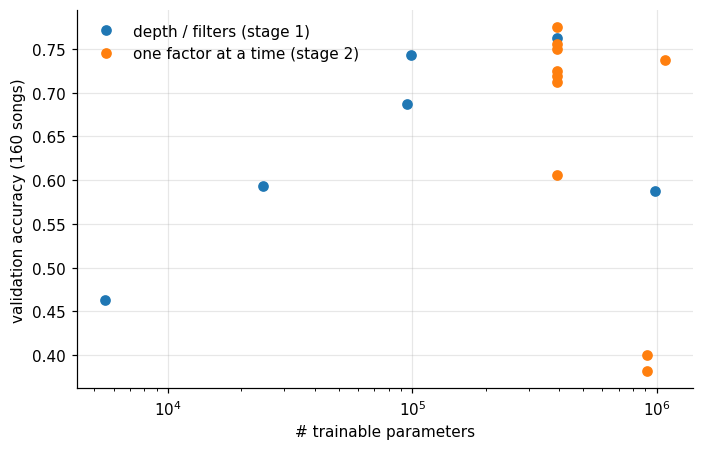

Best on validation: dropout_0.0 (0.775)


In [ ]:
# Validation accuracy vs number of trainable parameters
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for g, c, lab in (("depth",  "tab:blue",   "depth / filters (stage 1)"),
                  ("factor", "tab:orange", "one factor at a time (stage 2)")):
    d = res_df[res_df.group == g]
    ax.semilogx(d.params, d.best_val_acc, "o", color=c, label=lab)
ax.set_xlabel("# trainable parameters"); ax.set_ylabel(f"validation accuracy ({n_val} songs)")
ax.grid(alpha=.3); ax.legend(loc="upper left", frameon=False)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "task1_fig_val_vs_params.png", dpi=200); plt.show()

print("Best on validation:", res_df.iloc[0]["name"], f"({res_df.iloc[0].best_val_acc:.3f})")

- Validation accuracy grows with depth up to four blocks; beyond that the gains are within the noise.
- Most stage-2 changes are within about ±1 pp of the base network, i.e. at most two validation songs, so the selected configuration (dropout 0.0) is statistically tied with the base. It is kept because the selection rule is the validation accuracy.
- The very low scores of the five-block network, dropout 0.5 and the two rectangular kernels coincide with early-stopping runs that ended after only 4–21 epochs (see `best_epoch`). They look like optimisation artefacts of early stopping on a small validation set rather than architectural effects, and are re-examined in the report by retraining for a fixed number of epochs on several partitions.

## Final Model

The configuration with the highest validation accuracy is retrained on **all 799 training songs**, without a validation set, for the epoch at which it peaked in the search (`best_epoch`), keeping the same 40-epoch cosine schedule. It is then evaluated once on the 200 test songs.

In [ ]:
# ---- Selected configuration (highest validation accuracy) ----
best      = res_df.iloc[0]
best_name = best["name"]
BEST_CFG  = dict(filters=tuple(map(int, best.filters.split("-"))),
                 kernel=tuple(map(int, best.kernel.split("x"))),
                 dropout=float(best.dropout), augment=bool(best.augment), lr=float(best.lr),
                 size=(int(best.img_h), int(best.img_w)))
BEST_EPOCH = int(best.best_epoch)
print("Selected:", best_name)
print(BEST_CFG, "| retraining epochs:", BEST_EPOCH)

FINAL_FILES = dict(model   = RESULTS_DIR / "task1_best_cnn.keras",
                   preds   = RESULTS_DIR / "task1_test_predictions.csv",
                   probs   = RESULTS_DIR / "task1_test_probs.npy",
                   summary = RESULTS_DIR / "task1_final.csv")
y_test     = y_all[IDX_TEST]
test_songs = songs.song.to_numpy()[IDX_TEST]

Selected: dropout_0.0
{'filters': (32, 64, 128, 256), 'kernel': (3, 3), 'dropout': 0.0, 'augment': True, 'lr': 0.001, 'size': (128, 192)} | retraining epochs: 39


In [ ]:
if RETRAIN_FINAL or not all(p.exists() for p in FINAL_FILES.values()):
    # ---- Retrain on the full training set (same 40-epoch schedule, stopped at BEST_EPOCH) ----
    set_input_size(*BEST_CFG["size"])
    keras.backend.clear_session()
    final = train_model(SimpleCNN(filters=BEST_CFG["filters"], kernel=BEST_CFG["kernel"], dropout=BEST_CFG["dropout"]),
                        IDX_TRAIN, None, epochs=40, stop_epochs=BEST_EPOCH,
                        lr=BEST_CFG["lr"], augment=BEST_CFG["augment"])
    model = final["model"]

    # ---- Test set: evaluated once ----
    ds_test = make_ds(IDX_TEST, bs=128)
    model.predict(ds_test.take(1), verbose=0)                  # warm-up (compilation), not timed
    t0 = time.time(); logits = model.predict(ds_test, verbose=0)
    infer_s = time.time() - t0
    probs = tf.nn.softmax(logits).numpy()
    pred  = probs.argmax(1)

    final_info = dict(model="scratch_cnn", cfg=best_name, test_acc=float((pred == y_test).mean()),
                      params=final["params"], train_time_s=final["train_time"],
                      infer_ms_per_song=infer_s / len(IDX_TEST) * 1000)

    # ---- Save everything the analysis notebook needs (error overlap, ensembles, cost table) ----
    pd.DataFrame(dict(song=test_songs, y_true=y_test, y_pred=pred)).to_csv(FINAL_FILES["preds"], index=False)
    np.save(FINAL_FILES["probs"], probs)                       # same song order as task1_test_predictions.csv
    pd.DataFrame([final_info]).to_csv(FINAL_FILES["summary"], index=False)
    model.save(FINAL_FILES["model"])
    print("Final model retrained and saved.")
else:
    # ---- Reload the saved final model and predictions (reproduces the reported numbers exactly) ----
    print("Loading the saved final model and predictions (RETRAIN_FINAL = False).")
    model = keras.models.load_model(FINAL_FILES["model"])
    saved = pd.read_csv(FINAL_FILES["preds"])
    assert (saved.song.to_numpy() == test_songs).all() and (saved.y_true.to_numpy() == y_test).all(), \
        "Saved predictions do not match the current test split"
    probs = np.load(FINAL_FILES["probs"])
    pred  = probs.argmax(1)
    final_info = pd.read_csv(FINAL_FILES["summary"]).iloc[0].to_dict()

Loading the saved final model and predictions (RETRAIN_FINAL = False).


Test Results: Besides accuracy we report the Wilson 95 % interval and macro-averaged F1.

In [ ]:
def wilson_ci(k, n, z=1.96):
    # Wilson score interval for a proportion
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

n_test, n_ok = len(y_test), int((pred == y_test).sum())
acc = n_ok / n_test
lo, hi = wilson_ci(n_ok, n_test)
macro_f1 = f1_score(y_test, pred, average="macro")

print(f"Test accuracy : {acc:.3f}  ({n_ok}/{n_test} songs)  |  Wilson 95% CI [{lo:.3f}, {hi:.3f}]")
print(f"Macro-F1      : {macro_f1:.3f}")
print(f"Parameters    : {int(final_info['params']):,}")
print(f"Training time : {final_info['train_time_s']:.1f} s")
print(f"Inference     : {final_info['infer_ms_per_song']:.1f} ms/song")
print()
print(classification_report(y_test, pred, target_names=GENRES, digits=3))

Test accuracy : 0.825  (165/200 songs)  |  Wilson 95% CI [0.766, 0.871]
Macro-F1      : 0.825
Parameters    : 391,946
Training time : 66.5 s
Inference     : 8.4 ms/song

              precision    recall  f1-score   support

       blues      0.696     0.800     0.744        20
   classical      0.952     1.000     0.976        20
     country      0.882     0.750     0.811        20
       disco      0.762     0.800     0.780        20
      hiphop      0.900     0.900     0.900        20
        jazz      0.947     0.900     0.923        20
       metal      0.905     0.950     0.927        20
         pop      0.696     0.800     0.744        20
      reggae      0.882     0.750     0.811        20
        rock      0.667     0.600     0.632        20

    accuracy                          0.825       200
   macro avg      0.829     0.825     0.825       200
weighted avg      0.829     0.825     0.825       200



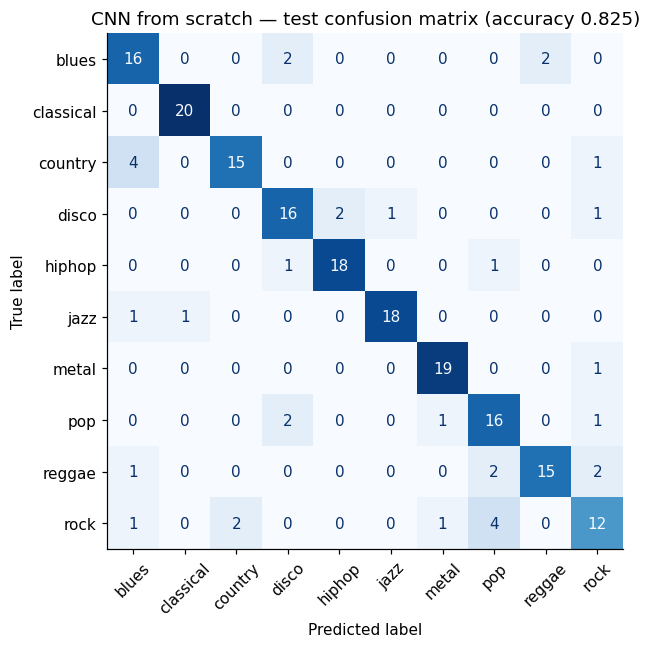

In [ ]:
# Confusion matrix on the 200 test songs
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=GENRES).plot(
    ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
ax.set_title(f"CNN from scratch — test confusion matrix (accuracy {acc:.3f})")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "task1_fig_confusion.png", dpi=200); plt.show()

In [ ]:
# Selected Architecture
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 192, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 192, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 192, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 96, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 96, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 96, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 48, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 48, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 48, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16, 24, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 12, 256)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,176,799 (4.49 MB)

 Trainable params: 391,946 (1.50 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 783,893 (2.99 MB)

**Next notebooks:** `task_2` (fine-tuning pretrained models) → `lab1_retraining` (descriptor models on the same split) → `multiseed_retraining` (five partitions) → `analysis` (research questions).